# Trajectories and adaptive integration

The {doc}`ODE tutorial <ode_integration>` advances a state one step at a time with the `ode_*_step` functions. To get a whole trajectory, `braintools.quad` has two drivers:

- `quad.odeint(f, y0, t0, t1, dt, *args, method=...)` runs any registered fixed-step stepper over a uniform time grid as one compiled `scan`;
- `quad.solve_ivp(f, (t0, t1), y0, *args, method='dopri5', rtol=..., atol=..., t_eval=...)` adapts the step size to meet an error tolerance, like `scipy.integrate.solve_ivp`.

Both are differentiable and work under `jit` and `vmap`. This tutorial covers:

1. `odeint` with fixed-step methods, and how their accuracy scales with the step size;
2. `solve_ivp` on the stiff-ish Van der Pol oscillator, checked against SciPy, with and without `t_eval`;
3. gradients through both drivers (`checkpoint=True`), used for a parameter sensitivity;
4. the method registry: `list_methods`, `get_method` and `register_method` with a custom stepper.

In [1]:
import time

import brainstate
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import scipy.integrate

from braintools import quad

jax.config.update('jax_enable_x64', True)  # float64, to compare errors down to 1e-10

## 1. Fixed-step trajectories with `odeint`

The harmonic oscillator $\ddot x = -\omega^2 x$ has the exact solution $x(t) = \cos \omega t$, $v(t) = -\omega \sin \omega t$ for $x(0) = 1$, $v(0) = 0$. The right-hand side takes the state first and the time second, `f(y, t, *args)` (SciPy uses `(t, y)`). Extra positional arguments after `dt` are passed on to `f`.

In [2]:
def oscillator(y, t, omega):
    x, v = y
    return jnp.stack([v, -omega ** 2 * x])


omega, T = 2.0, 10.0
y0 = jnp.array([1.0, 0.0])

ts, ys = quad.odeint(oscillator, y0, 0.0, T, 0.05, omega, method='rk4')
print('ts:', ts.shape, ' ys:', ys.shape, ' ys[0] == y0:', bool(jnp.all(ys[0] == y0)))

ts_s, ys_s = quad.odeint(oscillator, y0, 0.0, T, 0.05, omega, method='rk4', save_every=10)
print('save_every=10 -> ts:', ts_s.shape, ' first times:', ts_s[:3])

ts: (201,)  ys: (201, 2)  ys[0] == y0: True


save_every=10 -> ts: (21,)  first times: [0.  0.5 1. ]


`ts` holds the `n + 1 = 201` grid times including `t0`, and every leaf of `ys` gains a leading time axis. `save_every=10` keeps one state in ten, which saves memory on long runs without changing the steps.

`method` selects the stepper by name. Below, the forward Euler (order 1), midpoint (`'rk2'`, order 2) and classical Runge–Kutta (`'rk4'`, order 4) methods integrate the oscillator to $T = 10$ with step sizes from 0.04 down to 0.0025. The left panel shows trajectories at `dt = 0.05`, the right panel the final-time error. Looping over a few *configurations* in Python is fine; each `odeint` call is one compiled `scan` over the time steps.

euler  errors [2.15 0.88 0.4  0.19 0.09]  observed order [1.28 1.14 1.07 1.03]


rk2    errors [1.93e-02 4.81e-03 1.21e-03 3.03e-04 7.60e-05]  observed order [2.01 1.99 2.   2.  ]


rk4    errors [6.39e-06 3.83e-07 2.42e-08 1.52e-09 9.49e-11]  observed order [4.06 3.99 3.99 4.  ]


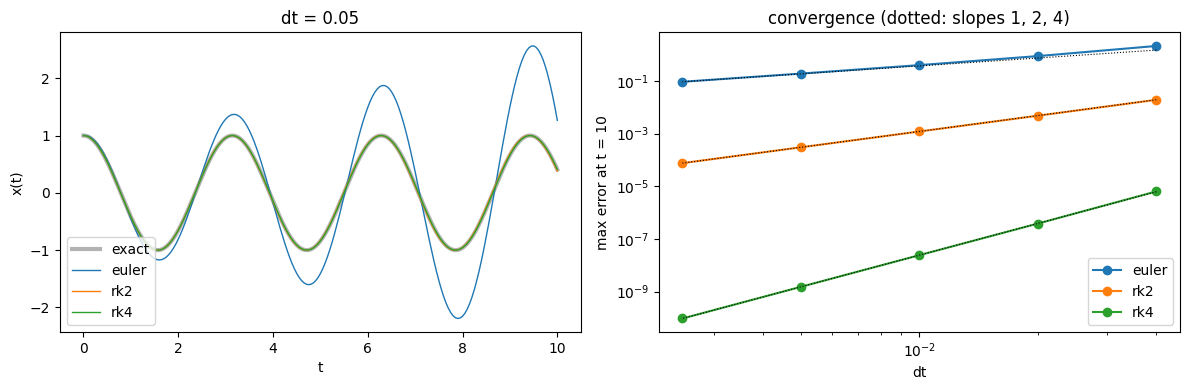

In [3]:
exact_T = jnp.array([jnp.cos(omega * T), -omega * jnp.sin(omega * T)])
dts = np.array([0.04, 0.02, 0.01, 0.005, 0.0025])
methods = ['euler', 'rk2', 'rk4']

errors = {}
for m in methods:
    errors[m] = np.array([float(jnp.max(jnp.abs(quad.odeint(oscillator, y0, 0.0, T, dt, omega, method=m)[1][-1]
                                               - exact_T)))
                          for dt in dts])
    orders = np.log2(errors[m][:-1] / errors[m][1:])
    print(f'{m:6s} errors {np.array2string(errors[m], precision=2)}  observed order {np.round(orders, 2)}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t_fine = np.linspace(0, T, 1000)
axes[0].plot(t_fine, np.cos(omega * t_fine), 'k', lw=3, alpha=0.3, label='exact')
for m in methods:
    ts_m, ys_m = quad.odeint(oscillator, y0, 0.0, T, 0.05, omega, method=m)
    axes[0].plot(ts_m, ys_m[:, 0], lw=1, label=m)
axes[0].set_xlabel('t')
axes[0].set_ylabel('x(t)')
axes[0].set_title('dt = 0.05')
axes[0].legend(loc='lower left')
for m, order in zip(methods, [1, 2, 4]):
    axes[1].loglog(dts, errors[m], 'o-', label=m)
    axes[1].loglog(dts, errors[m][-1] * (dts / dts[-1]) ** order, 'k:', lw=0.8)
axes[1].set_xlabel('dt')
axes[1].set_ylabel('max error at t = 10')
axes[1].set_title('convergence (dotted: slopes 1, 2, 4)')
axes[1].legend()
plt.tight_layout()
plt.show()

RK2 and RK4 converge at their nominal orders 2 and 4 from the start: halving `dt` divides the error by 4 and 16. Euler approaches order 1 only slowly (observed orders 1.28 down to 1.03), because on an oscillator it multiplies the amplitude by $\sqrt{1 + \omega^2 \Delta t^2}$ every step: at `dt = 0.05` its trajectory spirals outward, and at `dt = 0.04` its final error (2.15) exceeds the amplitude of the solution. RK4 at `dt = 0.04` (error 6.4e-6) is about 10,000 times more accurate than Euler with a 16 times smaller step (error 0.09 at `dt = 0.0025`).

## 2. Adaptive steps with `solve_ivp`

A fixed step must be small enough for the fastest part of the trajectory everywhere. The Van der Pol oscillator

$$\dot x = v, \qquad \dot v = \mu (1 - x^2) v - x$$

with $\mu = 10$ is a relaxation oscillator: slow drifts alternate with fast jumps. That makes it stiff-ish, and the right step size varies by orders of magnitude along the cycle. `solve_ivp` uses an embedded Runge–Kutta pair (`'dopri5'`, Dormand–Prince 5(4), by default): each step also yields an error estimate, the step is accepted when the error is below `atol + rtol * |y|`, and a PI controller picks the next step size.

Without `t_eval`, the solution holds the accepted steps. The output has a static length of `max_steps + 1` (here the default 4096 + 1), padded after the `n_steps` accepted steps:

In [4]:
def van_der_pol(y, t, mu):
    x, v = y
    return jnp.stack([v, mu * (1 - x ** 2) * v - x])


mu = 10.0
vdp_y0 = jnp.array([2.0, 0.0])
t_span = (0.0, 40.0)

sol = quad.solve_ivp(van_der_pol, t_span, vdp_y0, mu, rtol=1e-6, atol=1e-9)
n = int(sol.n_steps)
print(f'accepted steps: {n}, rejected: {int(sol.n_rejected)}, success: {bool(sol.success)}')
print('output length:', sol.ts.shape[0], ' last time:', float(sol.ts[n]))
h = np.diff(np.asarray(sol.ts[:n + 1]))
print(f'step size: min {h.min():.2e}, max {h.max():.2e}')

accepted steps: 859, rejected: 15, success: True
output length: 4097  last time: 40.0
step size: min 5.00e-04, max 8.32e-02


SciPy's `solve_ivp` with its own Dormand–Prince pair (`'RK45'`) at the same tolerances takes a similar number of steps. The counts differ somewhat because the step-size controllers differ (braintools uses a PI controller, SciPy a plain one):

In [5]:
def van_der_pol_scipy(t, y):
    return [y[1], mu * (1 - y[0] ** 2) * y[1] - y[0]]


sp = scipy.integrate.solve_ivp(van_der_pol_scipy, t_span, np.asarray(vdp_y0), method='RK45', rtol=1e-6, atol=1e-9)
print(f'scipy RK45: accepted steps {len(sp.t) - 1}, function evaluations {sp.nfev}, success {sp.success}')

scipy RK45: accepted steps 691, function evaluations 4490, success True


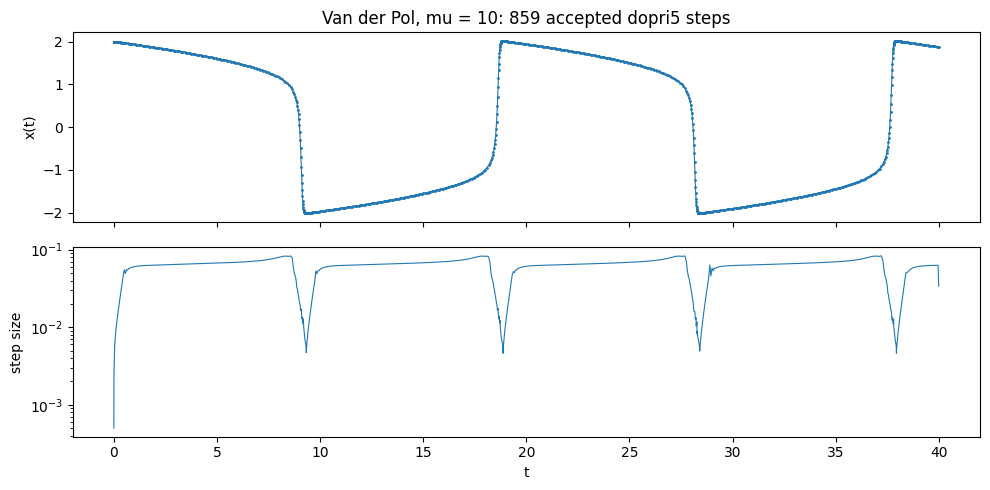

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(sol.ts[:n + 1], sol.ys[:n + 1, 0], '.-', ms=2, lw=0.8)
axes[0].set_ylabel('x(t)')
axes[0].set_title(f'Van der Pol, mu = {mu:g}: {n} accepted dopri5 steps')
axes[1].semilogy(sol.ts[1:n + 1], h, lw=0.8)
axes[1].set_ylabel('step size')
axes[1].set_xlabel('t')
plt.tight_layout()
plt.show()

The first step is small (the starting-step heuristic picks 5e-4). After that, the step size grows to about 0.08 on the slow branches and drops more than tenfold, to about 0.005, during each fast jump of $x$.

### Output at requested times: `t_eval`

With `t_eval`, the solution is returned at the requested times. `solve_ivp` shortens any step that would cross a `t_eval` point so that it lands on it, so the outputs have the accuracy of the solver itself rather than of an interpolant. This costs about one extra step per output point. Below, both solvers return 401 points; the reference is SciPy's 8th-order `'DOP853'` at `rtol = atol = 1e-12`:

braintools dopri5: accepted steps 1449, rejected 3 (compile + run 1.1 s)
max |x - reference|: braintools 5.0e-05, scipy RK45 1.7e-04


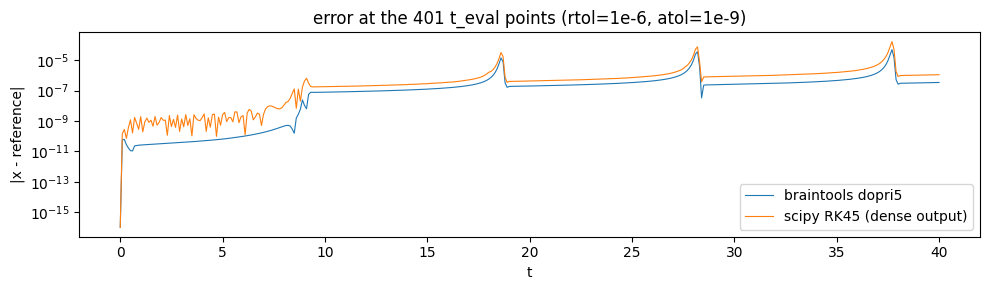

In [7]:
t_eval = jnp.linspace(*t_span, 401)

start = time.perf_counter()
sol_te = quad.solve_ivp(van_der_pol, t_span, vdp_y0, mu, rtol=1e-6, atol=1e-9, t_eval=t_eval)
jax.block_until_ready(sol_te.ys)
print(f'braintools dopri5: accepted steps {int(sol_te.n_steps)}, rejected {int(sol_te.n_rejected)} '
      f'(compile + run {time.perf_counter() - start:.1f} s)')

sp_te = scipy.integrate.solve_ivp(van_der_pol_scipy, t_span, np.asarray(vdp_y0), method='RK45',
                                  rtol=1e-6, atol=1e-9, t_eval=np.asarray(t_eval))
ref = scipy.integrate.solve_ivp(van_der_pol_scipy, t_span, np.asarray(vdp_y0), method='DOP853',
                                rtol=1e-12, atol=1e-12, t_eval=np.asarray(t_eval))

err_bt = np.abs(np.asarray(sol_te.ys[:, 0]) - ref.y[0])
err_sp = np.abs(sp_te.y[0] - ref.y[0])
print(f'max |x - reference|: braintools {err_bt.max():.1e}, scipy RK45 {err_sp.max():.1e}')

plt.figure(figsize=(10, 3))
plt.semilogy(t_eval, err_bt + 1e-16, lw=0.8, label='braintools dopri5')
plt.semilogy(t_eval, err_sp + 1e-16, lw=0.8, label='scipy RK45 (dense output)')
plt.xlabel('t')
plt.ylabel('|x - reference|')
plt.title('error at the 401 t_eval points (rtol=1e-6, atol=1e-9)')
plt.legend()
plt.tight_layout()
plt.show()

The maximum errors are 5.0e-5 for braintools and 1.7e-4 for SciPy. For both, the error jumps at each fast transition of $x$, where a small error in the timing of the jump becomes a large difference in $x$. SciPy interpolates its dense output at `t_eval`; braintools instead steps onto every output time. That costs extra steps (1449 accepted steps with `t_eval` against 859 without), but the outputs are as accurate as the steps themselves.

The `method` argument selects other embedded pairs. A higher-order pair takes fewer, more expensive steps at tight tolerances:

In [8]:
for m in ['rk23', 'dopri5', 'dopri8']:
    s = quad.solve_ivp(van_der_pol, t_span, vdp_y0, mu, method=m, rtol=1e-8, atol=1e-10, t_eval=t_eval)
    err = np.abs(np.asarray(s.ys[:, 0]) - ref.y[0]).max()
    print(f'{m:7s} accepted {int(s.n_steps):5d}  rejected {int(s.n_rejected):4d}  '
          f'max error {err:.1e}  success {bool(s.success)}')

rk23    accepted  4096  rejected    0  max error 3.9e+00  success False


dopri5  accepted  2632  rejected    0  max error 3.6e-07  success True


dopri8  accepted  1173  rejected    9  max error 8.9e-09  success True


At `rtol = 1e-8`, the 8th-order `'dopri8'` (DOP853) needs fewer than half the steps of `'dopri5'` (1173 against 2632) and is more accurate. The third-order `'rk23'` would need far more steps than either: it uses up the default `max_steps = 4096` attempts before reaching `t1 = 40`, so `success` is `False`. The outputs after the last accepted step hold that step's state, hence the large error. Raise `max_steps` (a static size, which costs compile time and memory) or use a higher-order pair.

## 3. Gradients through the solvers

Both drivers are differentiable with respect to the initial state, the extra arguments and the times. A common use is a **parameter sensitivity**: how much the trajectory changes when a parameter changes. Below, `jax.jacfwd` gives $\partial x(t) / \partial \mu$ at all 201 output times of a Van der Pol oscillator with $\mu = 1$, checked against a central finite difference.

dx(t)/dmu: (201,)  max |AD - finite difference| = 2.4e-07


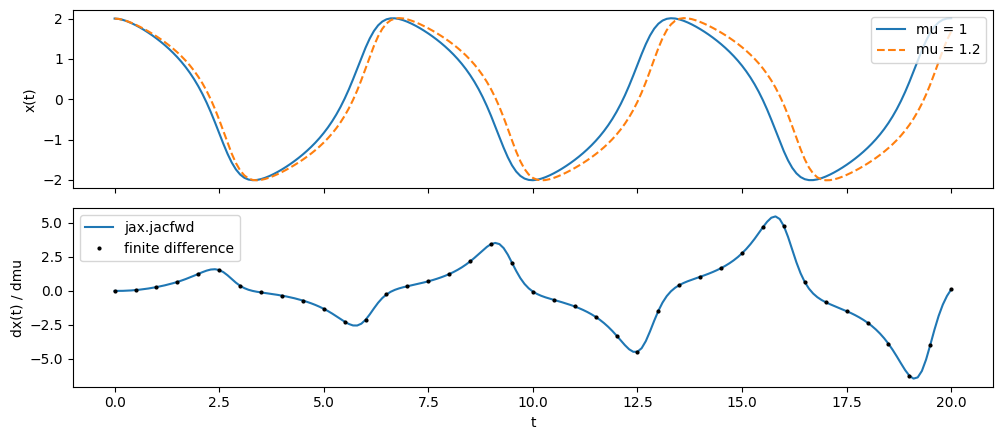

In [9]:
t_sens = jnp.linspace(0.0, 20.0, 201)


def x_traj(mu):
    s = quad.solve_ivp(van_der_pol, (0.0, 20.0), vdp_y0, mu, rtol=1e-10, atol=1e-12, t_eval=t_sens)
    return s.ys[:, 0]


sens = jax.jacfwd(x_traj)(1.0)
eps = 1e-5
sens_fd = (x_traj(1.0 + eps) - x_traj(1.0 - eps)) / (2 * eps)
print('dx(t)/dmu:', sens.shape, f' max |AD - finite difference| = {float(jnp.max(jnp.abs(sens - sens_fd))):.1e}')

fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
axes[0].plot(t_sens, x_traj(1.0), label='mu = 1')
axes[0].plot(t_sens, x_traj(1.2), '--', label='mu = 1.2')
axes[0].set_ylabel('x(t)')
axes[0].legend(loc='upper right')
axes[1].plot(t_sens, sens, label='jax.jacfwd')
axes[1].plot(t_sens[::5], sens_fd[::5], 'k.', ms=4, label='finite difference')
axes[1].set_ylabel('dx(t) / dmu')
axes[1].set_xlabel('t')
axes[1].legend(loc='upper left')
plt.tight_layout()
plt.show()

A larger $\mu$ lengthens the period, so the phase lag accumulates from cycle to cycle and the sensitivity oscillates with growing amplitude. The automatic derivative matches the finite difference to 2.4e-7.

Reverse mode (`jax.grad`) is what training and fitting use. It must keep the intermediate states of the forward pass, which for long rollouts can exhaust memory. `checkpoint=True` stores only some of them and recomputes the rest on the backward pass, so memory no longer grows with the number of steps; the values and gradients are the same. It is the default for `solve_ivp` (whose loop always has `max_steps` iterations) and opt-in for `odeint`:

In [10]:
def loss_odeint(omega, checkpoint):
    _, ys = quad.odeint(oscillator, y0, 0.0, 50.0, 0.001, omega, checkpoint=checkpoint)  # 50,000 steps
    return jnp.mean(ys[:, 0] ** 2)


def loss_ivp(mu, checkpoint):
    s = quad.solve_ivp(van_der_pol, (0.0, 20.0), vdp_y0, mu, rtol=1e-8, atol=1e-10,
                       t_eval=t_sens, checkpoint=checkpoint)
    return jnp.mean(s.ys[:, 0] ** 2)


for name, loss, p in [('odeint', loss_odeint, omega), ('solve_ivp', loss_ivp, 1.0)]:
    g_plain = jax.grad(loss)(p, False)
    g_ckpt = jax.grad(loss)(p, True)
    g_fd = (loss(p + eps, False) - loss(p - eps, False)) / (2 * eps)
    print(f'{name:9s} grad (checkpoint=False) {float(g_plain):+.8f}   (checkpoint=True) {float(g_ckpt):+.8f}'
          f'   finite difference {float(g_fd):+.8f}')

odeint    grad (checkpoint=False) +0.12332256   (checkpoint=True) +0.12332256   finite difference +0.12332254


solve_ivp grad (checkpoint=False) -0.10313317   (checkpoint=True) -0.10313317   finite difference -0.10313316


`solve_ivp` treats the accepted step sizes as constants when differentiating ("discretise, then optimise"), so its gradient is the exact gradient of the computed solution, and it agrees with the finite difference to the accuracy of the solve.

## 4. The method registry

`odeint` and `solve_ivp` look their `method` up in a registry of steppers, one table per equation kind (`'ode'`, `'sde'`, `'imex'`, `'dde'`). `list_methods` lists the names, and `get_method` returns the stepper; the full function name works too:

In [11]:
print('ODE methods:', quad.list_methods('ode'))
print('SDE methods:', quad.list_methods('sde'))
print("get_method('rk4') is ode_rk4_step:", quad.get_method('rk4') is quad.ode_rk4_step)
print("get_method('ode_dopri5_step') is ode_dopri5_step:", quad.get_method('ode_dopri5_step') is quad.ode_dopri5_step)
try:
    quad.get_method('rk5')
except KeyError as e:
    print('KeyError:', e)

ODE methods: ['bs32', 'dopri5', 'dopri8', 'euler', 'expeuler', 'heun', 'midpoint', 'ralston2', 'ralston3', 'rk2', 'rk23', 'rk3', 'rk4', 'rk45', 'rk45_dopri', 'rk4_38', 'rk87_dopri', 'rkf45', 'ssprk33']
SDE methods: ['euler', 'expeuler', 'heun', 'implicit_euler', 'milstein', 'srk2', 'srk3', 'srk4', 'tamed_euler']
get_method('rk4') is ode_rk4_step: True
get_method('ode_dopri5_step') is ode_dopri5_step: True
KeyError: "Unknown 'ode' method 'rk5'. Did you mean one of ['rk45', 'rkf45', 'rk4', 'rk3', 'rk2']? Available methods: ['bs32', 'dopri5', 'dopri8', 'euler', 'expeuler', 'heun', 'midpoint', 'ralston2', 'ralston3', 'rk2', 'rk23', 'rk3', 'rk4', 'rk45', 'rk45_dopri', 'rk4_38', 'rk87_dopri', 'rkf45', 'ssprk33']."


`register_method(name, fn)` adds a stepper. It must follow the convention of the built-in ODE steppers: `fn(f, y, t, *args, **kwargs)` returns the state after one step, with the step size read from `brainstate.environ.get_dt()` (`odeint` sets it from its `dt` argument).

As an example, the function below builds an explicit Runge–Kutta stepper from a Butcher tableau, and registers Kutta's classical third-order method under the name `'kutta3'`. `overwrite=True` lets the cell run twice; without it, registering an existing name raises `ValueError`. Once registered, `odeint` accepts the new name, and the convergence study of section 1 confirms the order:

In [12]:
def make_explicit_rk(a, b, c):
    """Return an ODE stepper for the explicit Runge-Kutta tableau (a, b, c)."""

    def step(f, y, t, *args, **kwargs):
        dt = brainstate.environ.get_dt()
        ks = []
        for i in range(len(b)):  # loop over the stages of one step (unrolled at trace time)
            yi = y + dt * sum(a[i][j] * ks[j] for j in range(i)) if i else y
            ks.append(f(yi, t + c[i] * dt, *args, **kwargs))
        return y + dt * sum(bi * k for bi, k in zip(b, ks))

    return step


kutta3 = make_explicit_rk(a=[[], [1 / 2], [-1, 2]], b=[1 / 6, 2 / 3, 1 / 6], c=[0, 1 / 2, 1])
quad.register_method('kutta3', kutta3, overwrite=True)
print("'kutta3' registered:", 'kutta3' in quad.list_methods('ode'))

err_k3 = np.array([float(jnp.max(jnp.abs(quad.odeint(oscillator, y0, 0.0, T, dt, omega, method='kutta3')[1][-1]
                                         - exact_T)))
                   for dt in dts])
print('kutta3 errors', np.array2string(err_k3, precision=2),
      ' observed order', np.round(np.log2(err_k3[:-1] / err_k3[1:]), 2))

'kutta3' registered: True


kutta3 errors [7.55e-04 9.59e-05 1.21e-05 1.52e-06 1.90e-07]  observed order [2.98 2.99 2.99 3.  ]


Halving the step divides the error by about 8, as expected for a third-order method. The stage loop inside the stepper is a plain Python loop over the three stages of *one* step: it is unrolled when `odeint` traces the stepper once, while the loop over time steps stays inside the compiled `scan`.

`solve_ivp` additionally needs an error estimate and the order of that estimate for its step-size controller, so it accepts only the built-in embedded pairs, which the error message lists. A registered stepper such as `'kutta3'` works with `odeint` but is rejected by `solve_ivp` with a `ValueError`:

In [13]:
try:
    quad.solve_ivp(oscillator, (0.0, 1.0), y0, omega, method='kutta3')
except ValueError as e:
    print('ValueError:', e)

ValueError: Method 'kutta3' has no embedded error estimate. Adaptive methods: ['bs32', 'dopri5', 'dopri8', 'rk23', 'rk45', 'rk45_dopri', 'rk87_dopri', 'rkf45'].


For the single-step functions behind these drivers, see the {doc}`ODE <ode_integration>`, {doc}`SDE <sde_integration>` and {doc}`IMEX and delay <imex_and_dde_integration>` tutorials; for fitting models with `odeint` and `solve_ivp`, the {doc}`model-fitting tutorial <../fit/01_fitting_models>`; and for every parameter, the {doc}`API reference <../apis/quad>`.